**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 7**
Análisis de Componentes Principales (PCA)

---

*   NOMBRE: Emilio Garza Castañeda, Samuel Enrique Garza Montemayor, Luis Pablo García
*   MATRÍCULA: A01732580, A00829926, A01114202

En esta actividad trabajarás con el archivo `automobile_dataset.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de automóviles, disponible en el repositorio UCI Machine Learning.

Los datos fueron recopilados para analizar diferentes aspectos de los vehículos y sus precios, e incluyen información sobre el fabricante, tipo de motor, dimensiones, peso, rendimiento de combustible y otras especificaciones técnicas. Los indicadores incluidos son:

* `symboling`: Nivel de riesgo del seguro del automóvil, de -3 (bajo riesgo) a +3 (alto riesgo)
* `normalized_losses`: Pérdidas normalizadas del seguro (valor numérico de la aseguradora, algunas veces faltante)
* `make`: Marca del automóvil (por ejemplo, Audi, BMW, Honda)
* `fuel_type`: Tipo de combustible (gasolina o diésel)
* `aspiration`: Tipo de aspiración del motor (normal o turbo)
* `num_doors`: Número de puertas del automóvil (dos o cuatro)
* `body_style`: Estilo de carrocería (sedán, hatchback, wagon, hardtop, convertible)
* `drive_wheels`: Tipo de tracción (fwd: delantera, rwd: trasera, 4wd: en las cuatro ruedas)
* `engine_location`: Ubicación del motor (delantero o trasero)
* `wheel_base`: Distancia entre ejes (en pulgadas)
* `length`: Largo total del automóvil (en pulgadas)
* `width`: Ancho total del automóvil (en pulgadas)
* `height`: Altura total del automóvil (en pulgadas)
* `curb_weight`: Peso del automóvil sin carga (en libras)
* `engine_type`: Tipo de motor (OHV, OHC, DOHC, etc.)
* `num_cylinders`: Número de cilindros del motor
* `engine_size`: Tamaño del motor (en cc)
* `fuel_system`: Sistema de combustible (por ejemplo, mpfi, 2bbl, 4bbl)
* `bore`: Diámetro del cilindro (en pulgadas)
* `stroke`: Carrera del pistón (en pulgadas)
* `compression_ratio`: Relación de compresión del motor
* `horsepower`: Potencia del motor (en caballos de fuerza)
* `peak_rpm`: Revoluciones máximas por minuto
* `city_mpg`: Rendimiento de combustible en ciudad (millas por galón)
* `highway_mpg`: Rendimiento de combustible en carretera (millas por galón)
* `price`: Precio del automóvil (en dólares estadounidenses) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [90]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

1. Descarga el archivo: `automobile_dataset.csv` y guarda, en un dataframe (`cars_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Al revisar los primeros registros, notarás que la columna `normalized_losses` contiene el símbolo `?`. Esto sugiere que se utilizó para indicar valores faltantes. Identifica todas las columnas que presentan este símbolo.
* Sustituye el símbolo `?` por valores faltantes (`NaN`) y convierte las columnas al tipo de dato adecuado. Esto es necesario porque la presencia del símbolo pudo haber hecho que pandas las interpretara como object, aunque en realidad no lo fueran.

In [91]:
cars_df = pd.read_csv('/content/automobile_dataset.csv')

print(cars_df.info())

cars_df

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cylinders      205 non-null    int64  
 16  engine_size        205 non

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.4,23.0,106,4800,26,27,22470


In [92]:
nulls = cars_df.columns[cars_df.eq('?').any()].to_list()
print(nulls)
cars_df = cars_df.replace('?', pd.NA)
for col in nulls:
  cars_df[col] = pd.to_numeric(cars_df[col],errors='coerce')

cars_df.info()

['normalized_losses', 'bore', 'stroke', 'horsepower', 'peak_rpm']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  164 non-null    float64
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cyli

# Análisis exploratorio de datos (univariado)

2. Antes de iniciar con el análisis univariado, verifica si hay registros duplicados e imprime el porcentaje de faltantes por columna.
* Obtén las estadísticas descriptivas, separado las numéricas (incluye asimetría y curtosis) y las categóricas (incluye tablas de frecuencias).
* Genera histogramas para las numéricas y diagramas de barras para las categóricas.

In [93]:
cars_df.duplicated().sum()

np.int64(0)

In [94]:
cat_cols = cars_df.select_dtypes(include=['object','category']).columns.tolist()
num_cols = cars_df.select_dtypes(include=['float64','int64']).columns.tolist()

print((cars_df.isnull().sum() / len(cars_df))*100)
print(cars_df.describe())

for col in num_cols:
  print(f'Skew de {col}: ',cars_df[col].skew())
  print(f'Curtosis de {col}: ',cars_df[col].kurt())
  print('\n')

for col in cat_cols:
  print(f'\nFrecuencias de {col}:')
  print(cars_df[col].value_counts(dropna=True))


symboling             0.00000
normalized_losses    20.00000
make                  0.00000
fuel_type             0.00000
aspiration            0.00000
num_doors             0.00000
body_style            0.00000
drive_wheels          0.00000
engine_location       0.00000
wheel_base            0.00000
length                0.00000
width                 0.00000
height                0.00000
curb_weight           0.00000
engine_type           0.00000
num_cylinders         0.00000
engine_size           0.00000
fuel_system           0.00000
bore                  1.95122
stroke                1.95122
compression_ratio     0.00000
horsepower            0.97561
peak_rpm              0.97561
city_mpg              0.00000
highway_mpg           0.00000
price                 0.00000
dtype: float64
        symboling  normalized_losses  wheel_base      length       width  \
count  205.000000         164.000000  205.000000  205.000000  205.000000   
mean     0.834146         122.000000   98.756585  174

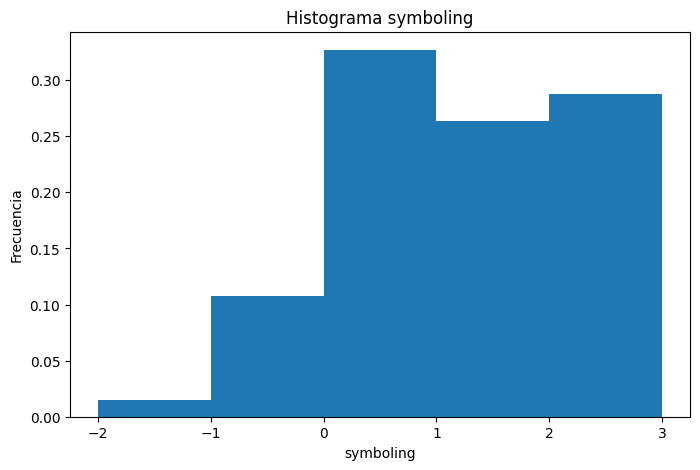

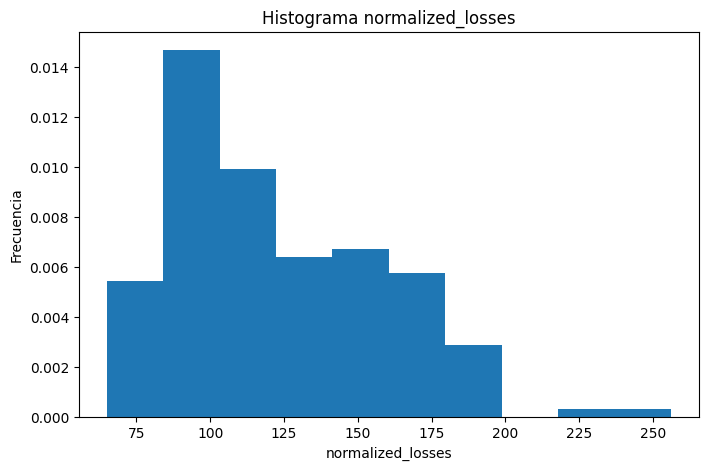

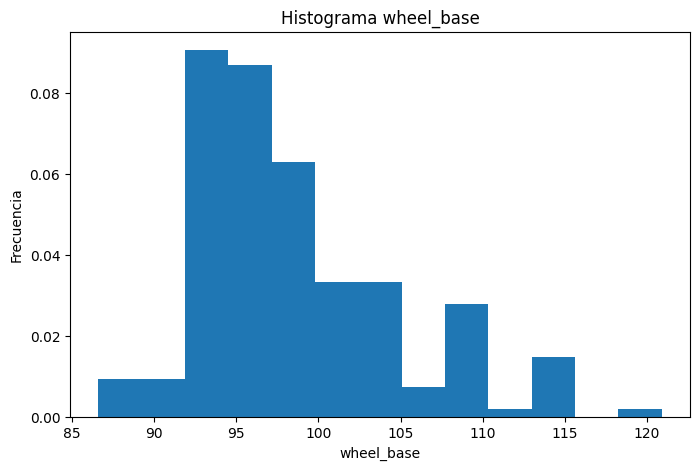

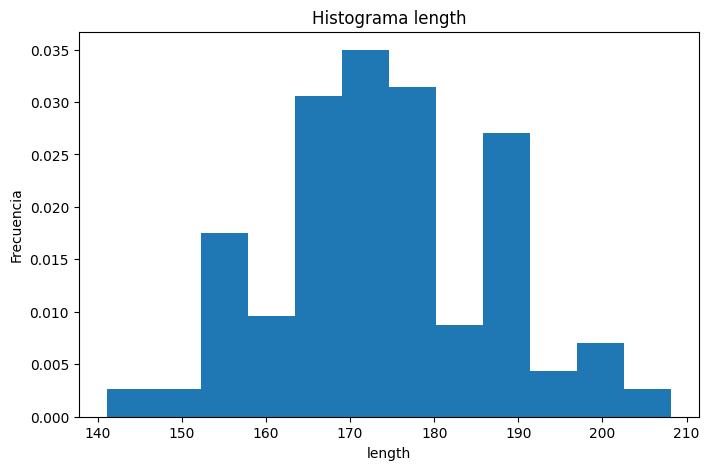

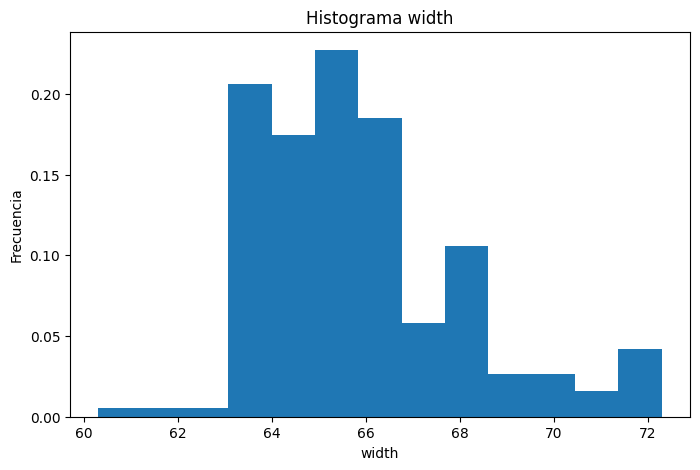

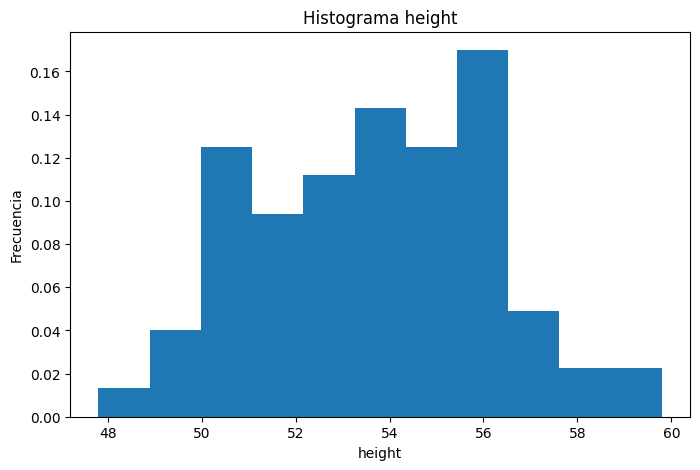

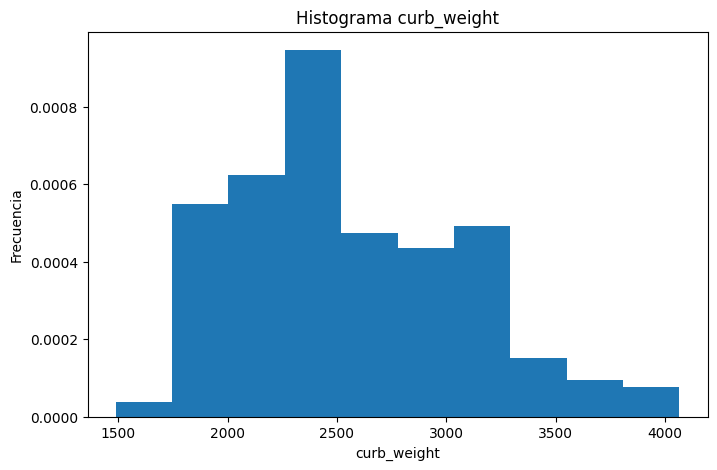

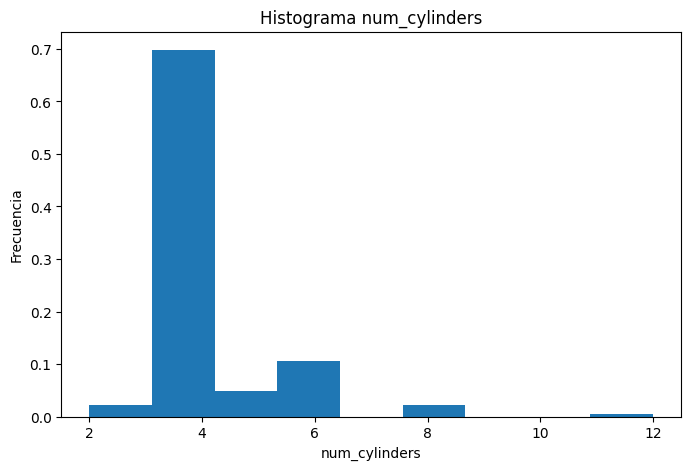

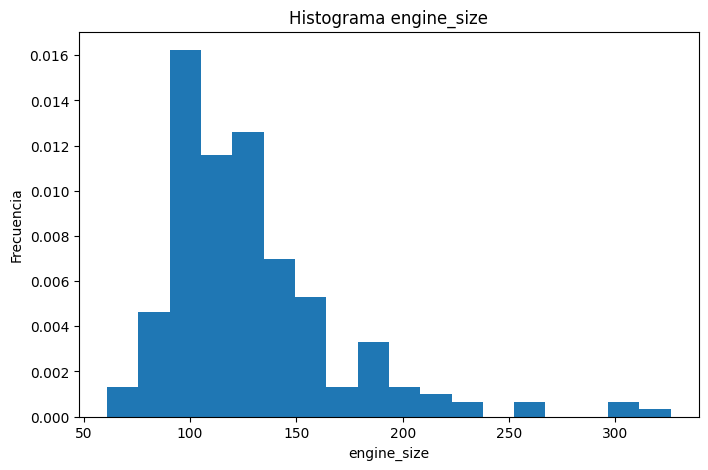

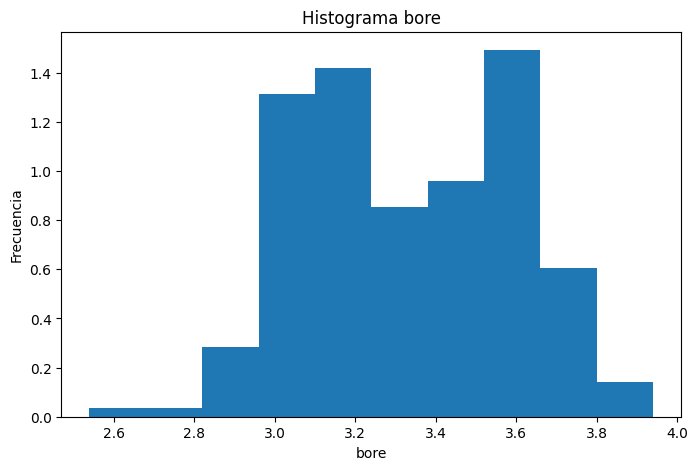

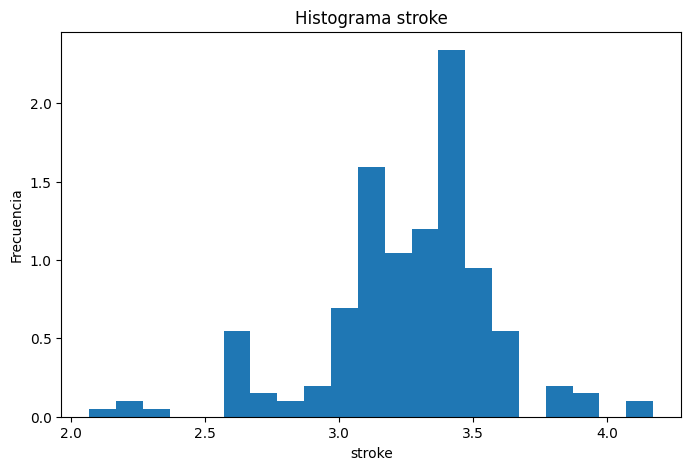

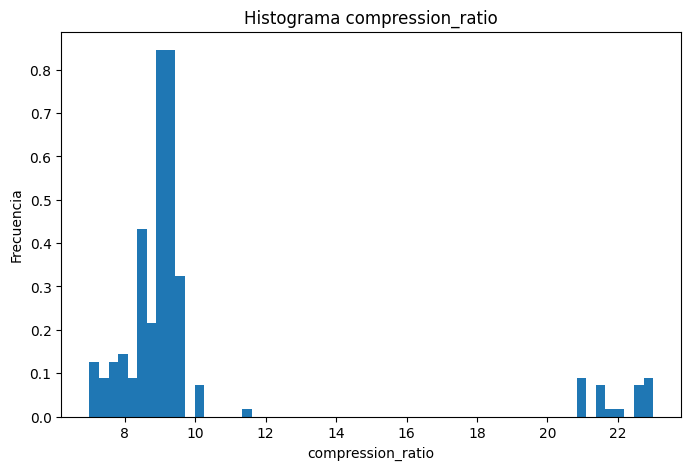

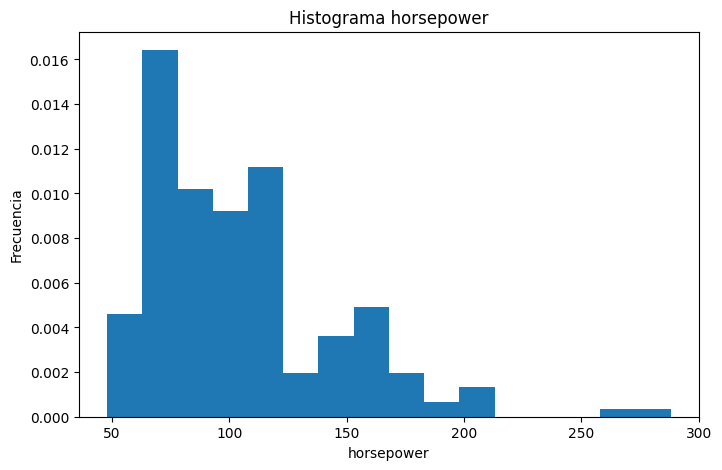

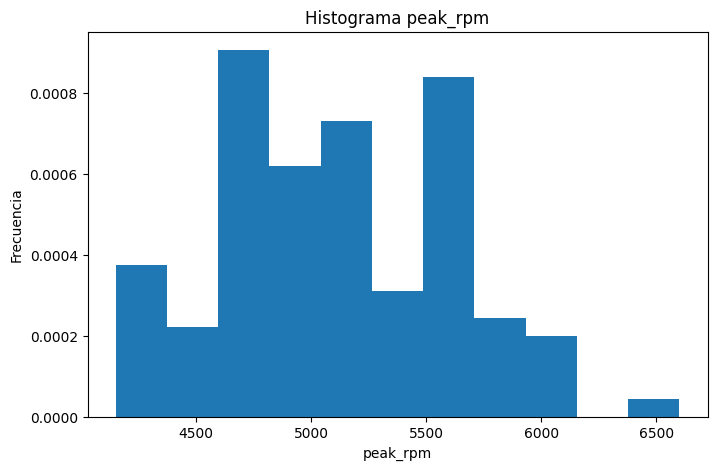

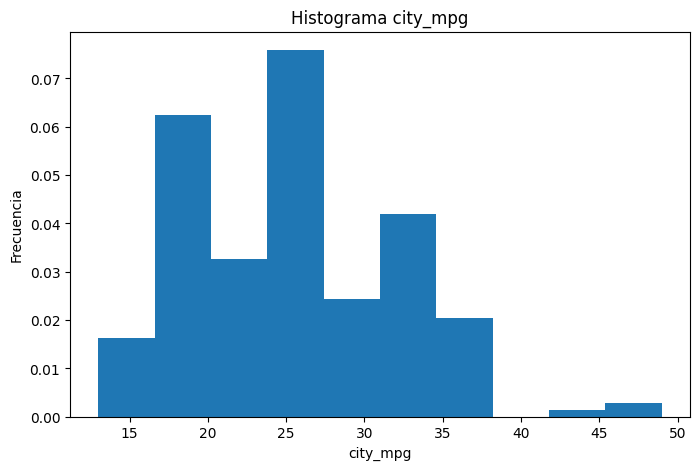

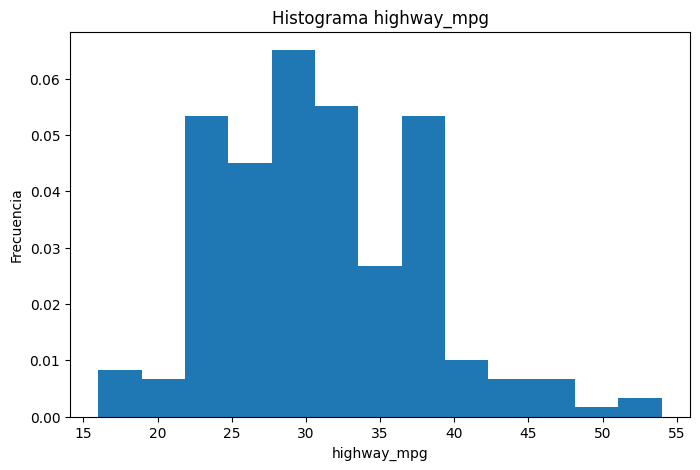

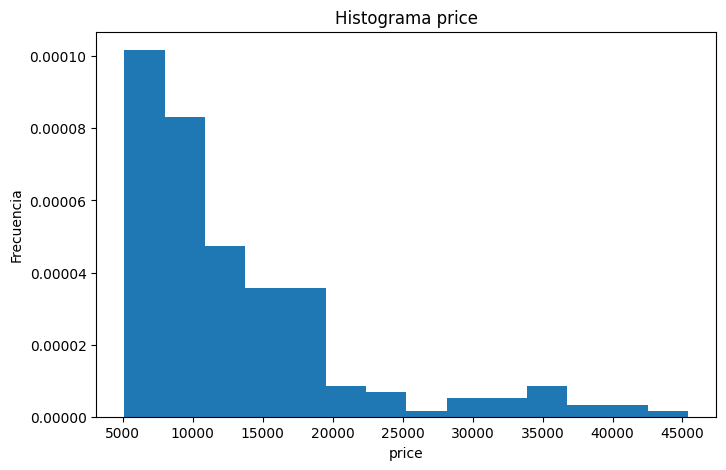

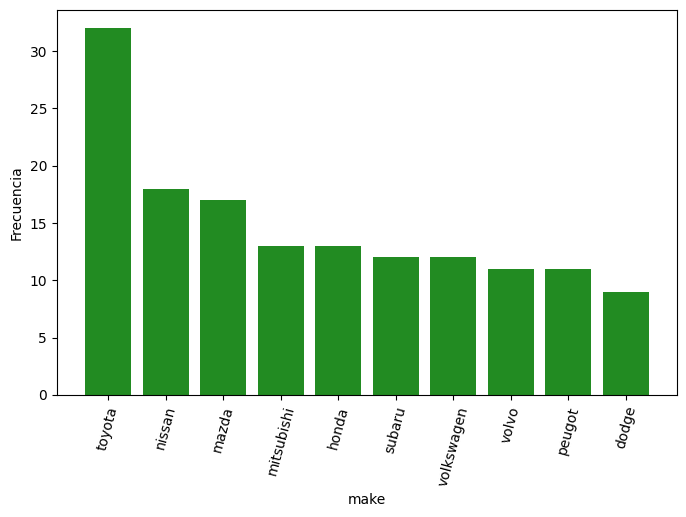

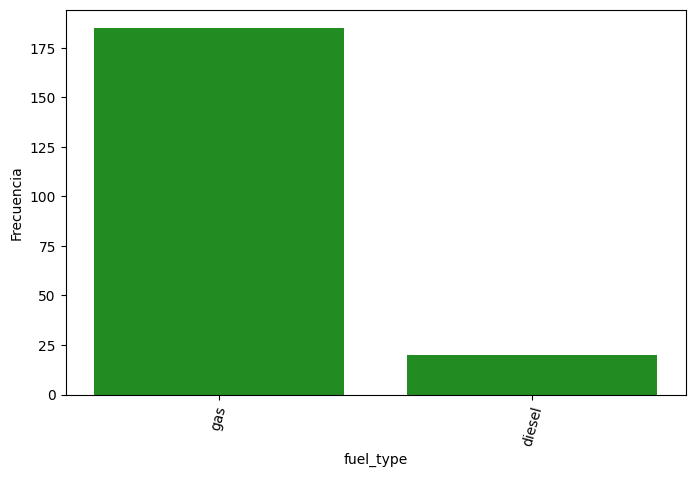

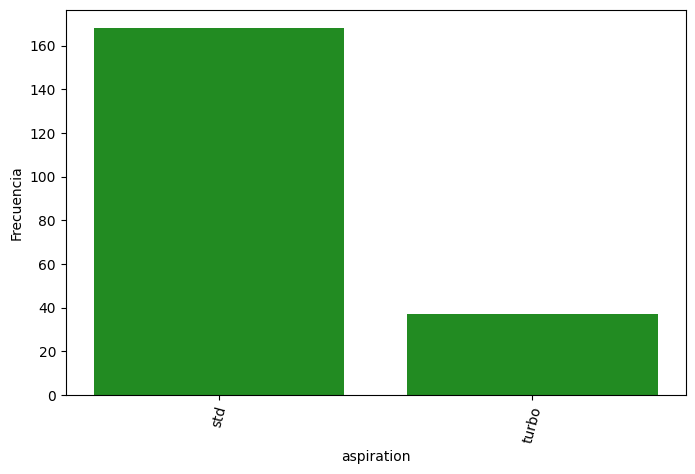

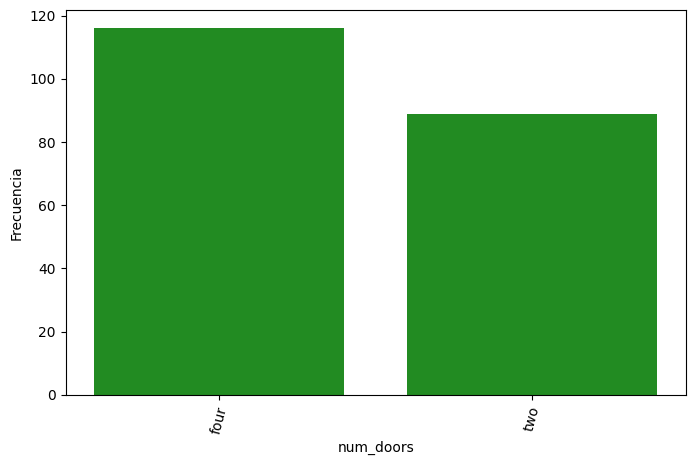

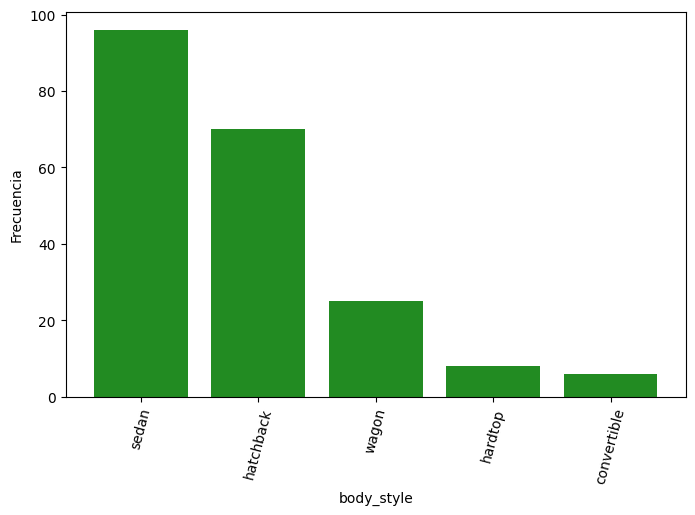

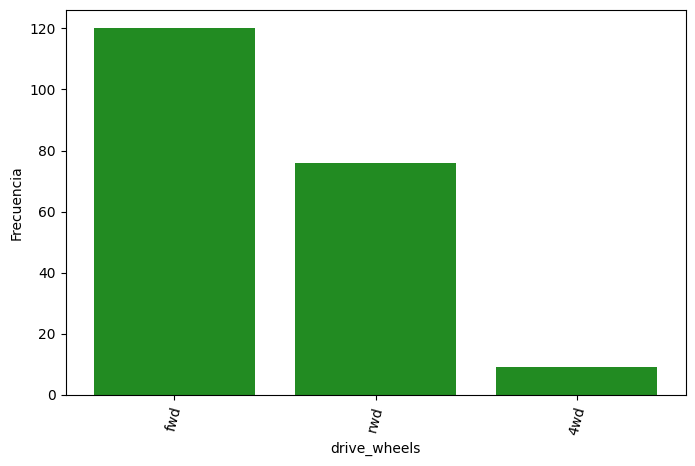

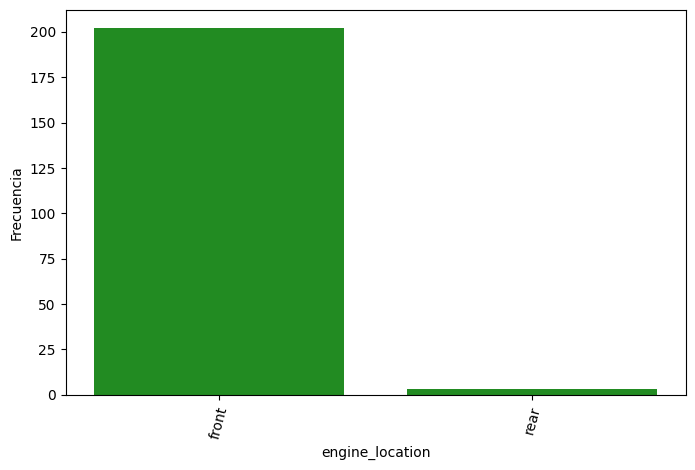

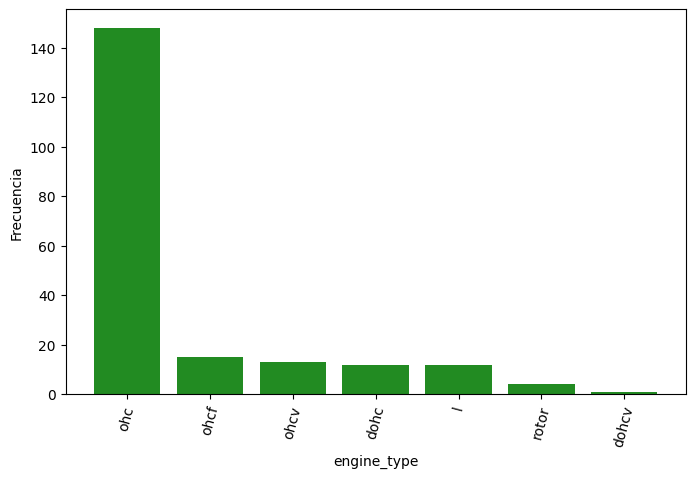

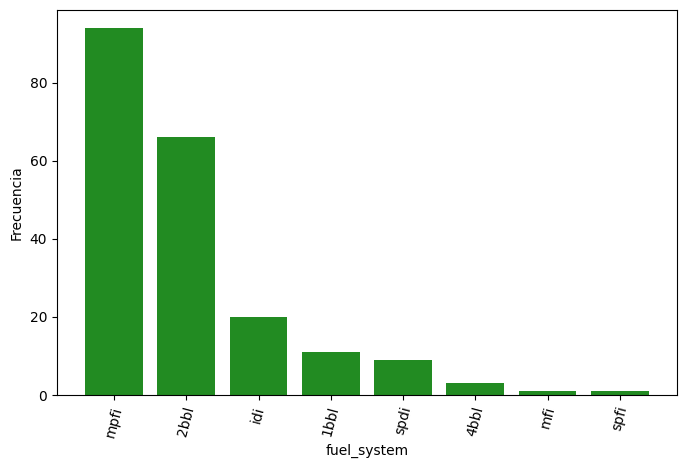

In [95]:
for col in num_cols:
  plt.figure(figsize=(8,5))
  plt.hist(cars_df[col],bins='auto',density=True)
  plt.title(f'Histograma {col}')
  plt.xlabel(col)
  plt.ylabel('Frecuencia')
  plt.show()

for column in cat_cols:
  count = cars_df[column].value_counts().head(10)
  plt.figure(figsize=(8,5))
  plt.bar(count.index.astype(str), count.values,color='forestgreen')
  plt.xticks(rotation=75)
  plt.xlabel(column)
  plt.ylabel('Frecuencia')
  plt.show()

# Análisis exploratorio de datos (bivariado)

3. Genera algunos gráficos bivariados para familiarizarte con el conjunto de datos:
* Gráfico de barras apiladas normalizadas que muestra la distribución de los tipos de tracción para cada fabricante.
* Diagrama de cajas para visualizar cómo se distribuye el precio de los automóviles según el estilo de carrocería. Esto permitirá comparar la mediana, los cuartiles y la presencia de valores atípicos entre los diferentes tipos de carrocería.
* Gráfico de barras que muestre los 10 automóviles más caros, ordenados de mayor a menor precio, con cada barra diferenciada con color por fabricante.
* Diagrama de dispersión para explorar la relación entre el tamaño del motor y el precio de los automóviles. Diferencia con colores los puntos según el tipo de aspiración y con el tamaño de los puntos el número de puertas.

**Nota.** Debes incluir en cada gráfico una conclusión de lo observado.

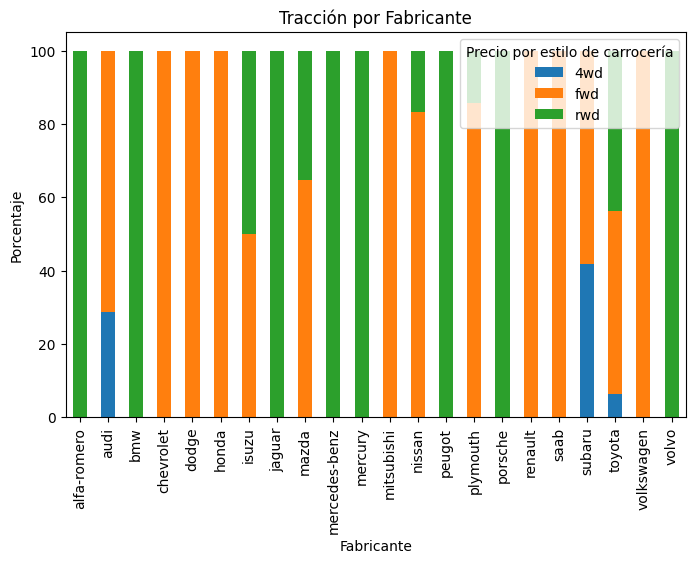

In [96]:
#grafica de barras normalizada

norm = pd.crosstab(cars_df['make'],cars_df['drive_wheels'],normalize = 'index') *100

norm.plot(kind='bar',stacked=True,figsize=(8,5))
plt.title('Tracción por Fabricante')
plt.xlabel('Fabricante')
plt.ylabel('Porcentaje')
plt.legend(title='Precio por estilo de carrocería', loc = 'upper right')
plt.xticks(rotation=90)
plt.show()


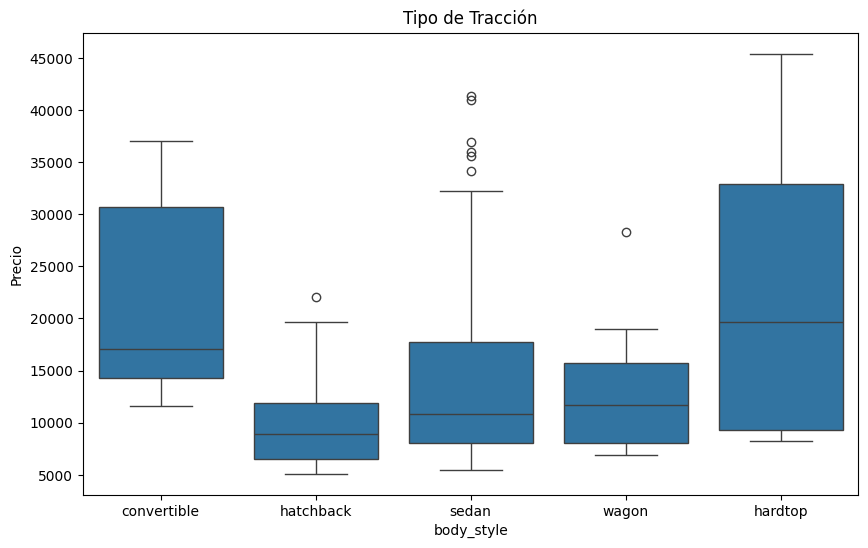

In [97]:
#boxplots
plt.figure(figsize=(10,6))
sns.boxplot(data=cars_df,
            x='body_style',
            y='price')

plt.title('Distribución de Precios')
plt.title('Tipo de Tracción')
plt.ylabel('Precio')
plt.show()

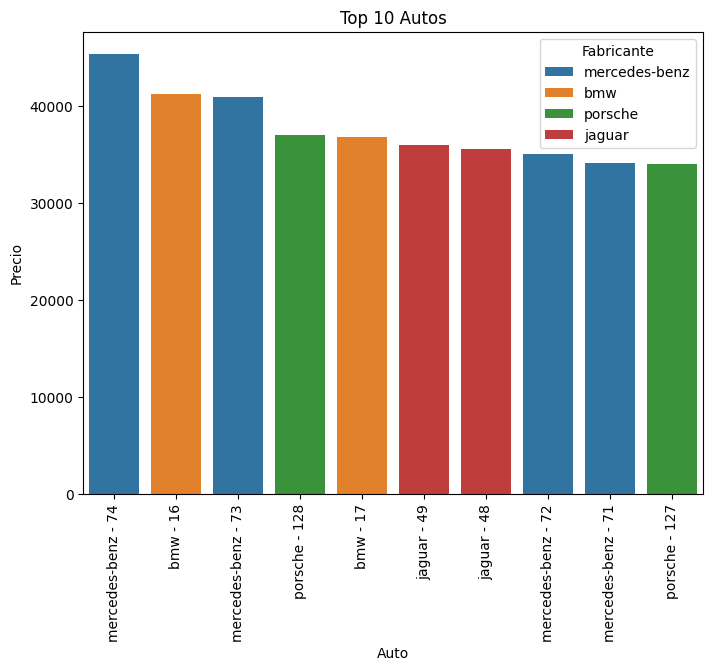

In [98]:
#Grafico de Barras top 10 carros
plt.figure(figsize=(8,6))
top = cars_df.nlargest(10,'price').copy()
top['auto'] = top['make'] + ' - ' + top.index.astype(str)
sns.barplot(data = top, x='auto',y='price',hue='make',dodge=False)
plt.title('Top 10 Autos')
plt.xlabel('Auto')
plt.ylabel('Precio')
plt.xticks(rotation=90)
plt.legend(title='Fabricante')
plt.show()

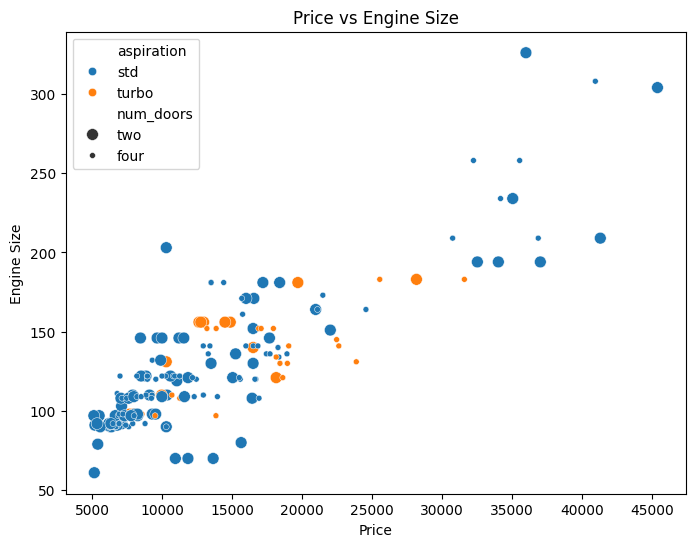

In [99]:
#Scatter
plt.figure(figsize=(8,6))

sns.scatterplot(data=cars_df,x='price',y='engine_size',hue='aspiration',size='num_doors')

plt.title('Price vs Engine Size')
plt.xlabel('Price')
plt.ylabel('Engine Size')
plt.show()

4. Genera un mapa de calor de la matriz de correlación entre las variables numéricas del conjunto de datos, mostrando los valores de correlación en cada celda.
* ¿Cuáles son las tres variables más correlacionadas con el precio?

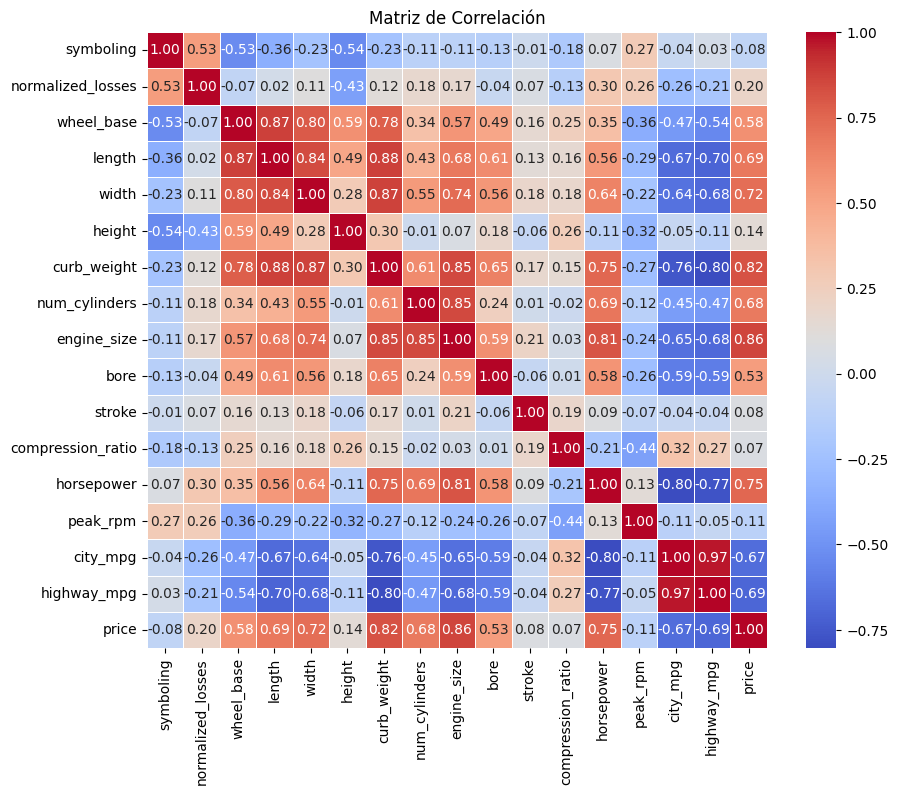

In [100]:

corr_matrix = cars_df.select_dtypes(include=["number"]).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5
)
plt.title("Matriz de Correlación")
plt.show()

In [101]:
top_3_corr = (
    corr_matrix["price"].drop("price").abs().sort_values(ascending=False).head(3)
)

print("Las 3 variables más correlacionadas con el precio:")
print(top_3_corr)

Las 3 variables más correlacionadas con el precio:
engine_size    0.860343
curb_weight    0.819817
horsepower     0.749844
Name: price, dtype: float64


En el análisis de correlación se observa que existen muchos pares de variables altamente correlacionadas, lo que puede afectar el desempeño de los modelos de regresión. PCA resulta útil no solo para reducir la dimensionalidad, sino también porque los componentes principales son ortogonales entre sí, es decir, tienen correlación cero, evitando problemas de multicolinealidad. Esto lo podrás comprobrar más adelante.

# Ingeniería de características

5. Realiza las siguientes operaciones de ingeniería de características en las variables numéricas:
* Considera `price` como la variable objetivo y guárdala en `y`. Separa los predictores numéricos en `X`. Con base en estos datos, ¿cuántos componentes principales se generarán al aplicar PCA?
* Aplica `SimpleImputer` sobre `X` para tratar los valores faltantes, justificando la estrategia de imputación seleccionada.
* Realiza el escalamiento del conjunto `X` ya imputado, para que todas las variables contribuyan equitativamente y ninguna domine el análisis por tener una escala mayor.

PCA está diseñado principalmente para variables numéricas y funciona encontrando combinaciones lineales de las variables originales que capturan la mayor varianza en los datos. Normalmente se recomienda eliminar las variables categóricas antes de aplicar PCA y luego concatenarlas nuevamente con los resultados de PCA si se desea.

In [102]:
y = cars_df.price
X = cars_df.select_dtypes(include=["number"]).drop(columns='price', errors="ignore")

In [103]:

cols_with_nulls = X.columns[X.isna().sum() > 0]

if len(cols_with_nulls) > 0:

  X_nulls = X[cols_with_nulls]

  Q1 = X_nulls.quantile(0.25)
  Q3 = X_nulls.quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  nulls_count = X_nulls.isna().sum()
  outliers_count = ((X_nulls < lower_bound) | (X_nulls > upper_bound)).sum()
  outliers_percentage = (outliers_count / len(X_nulls)) * 100

  imputation_audit = pd.DataFrame(
      {
          "Valores_Nulos": nulls_count,
          "Outliers_1.5IQR": outliers_count,
          "Porcentaje_Outliers_%": outliers_percentage,
      }
  )
imputation_audit

,Valores_Nulos,Outliers_1.5IQR,Porcentaje_Outliers_%
normalized_losses,41,1,0.487805
bore,4,0,0.000000
stroke,4,20,9.756098
horsepower,2,6,2.926829
peak_rpm,2,2,0.975610


In [104]:
imputer = SimpleImputer(strategy="median")
X_imputed_array = imputer.fit_transform(X)
X_imputed = pd.DataFrame(X_imputed_array, columns=X.columns)

Podemos ver en la tabla de arriba outliers en las variables con nulos (teniendo a  stroke con un 9.76% de outliers). Por esta razón se selecciona la mediana para imputar los nulos al ser una técnica que evita el sesgo por outliers


In [105]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_imputed), columns=X.columns)

6. Aplica `PCA` a los datos escalados para proyectarlos en el nuevo espacio de vectores.
* Asigna nombres descriptivos a los componentes principales en el dataframe resultante, utilizando la convención PC1, PC2, PC3, y así sucesivamente.
* Genera un mapa de calor con la matriz de correlaciones de los componentes principales para verificar que sean independientes entre sí.

In [106]:
from sklearn.decomposition import PCA

pca = PCA()
X_pca_array = pca.fit_transform(X_scaled)

pc_columns = [f"PC{i+1}" for i in range(X_pca_array.shape[1])]

X_pca = pd.DataFrame(X_pca_array, columns=pc_columns)

X_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16
0,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.288788,-1.088415,-0.347735,-0.474581,0.267610,-0.273617,0.362346,0.185204,0.003853
1,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.288788,-1.088415,-0.347735,-0.474581,0.267610,-0.273617,0.362346,0.185204,0.003853
2,0.634430,-1.372747,0.872496,0.998222,1.834717,-0.774751,-0.515065,1.370499,-1.130802,-1.013703,0.502983,0.657052,0.174955,-0.008520,0.118635,-0.111688
3,-0.361470,-0.919214,0.451578,-1.489124,-0.269938,-0.789900,0.000484,0.400032,0.293338,0.168137,0.039239,-0.022832,-0.078891,-0.391786,0.009265,0.053641
4,1.172393,-1.794960,0.183773,-1.083812,0.113486,-0.861858,-0.353900,0.870186,0.015429,-0.447054,-0.055376,-0.416053,-0.049431,0.079357,-0.198402,0.046303
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,2.573926,1.392679,-1.504231,-0.659681,0.072287,0.207617,0.654227,-1.192231,0.179134,0.931676,-0.169067,-0.177188,0.093562,0.041206,0.007081,-0.037681
201,3.315096,0.840401,-1.732448,-0.576819,0.157194,0.464028,0.628639,-1.026555,0.067092,0.468305,0.363496,0.328665,0.483914,-0.297624,0.034482,-0.028020
202,3.679110,0.477877,-1.795559,0.725820,0.508152,-1.014712,0.594154,-0.517893,-0.178130,0.446426,-0.381930,-0.517726,0.006614,-0.271891,-0.021254,-0.136048
203,2.547015,3.031699,1.741772,0.308113,0.775935,-1.625219,1.363060,0.290099,-1.453928,-0.592072,-0.154183,-0.148941,0.079162,-0.218676,-0.347104,0.172761


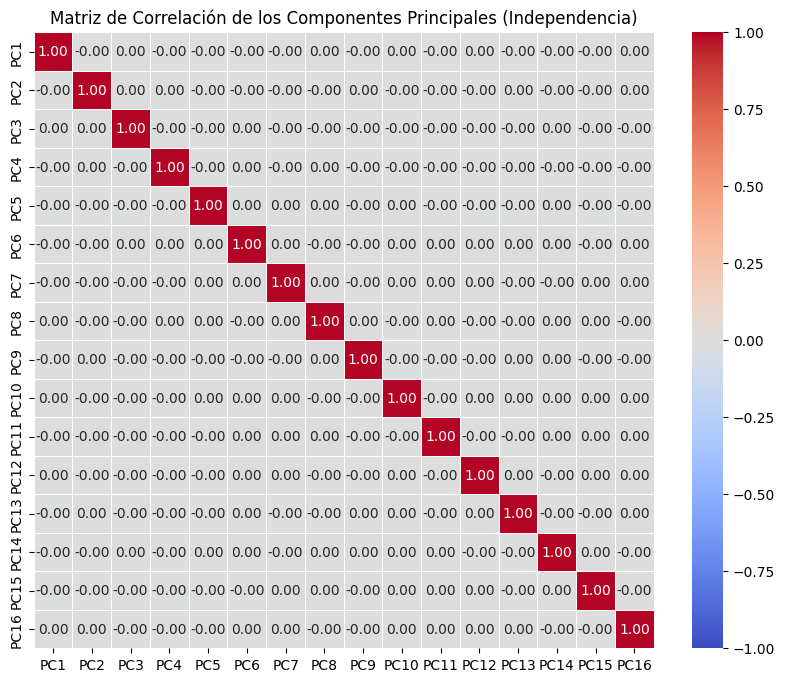

In [107]:
corr_pca = X_pca.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_pca,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5,
)
plt.title(
    "Matriz de Correlación de los Componentes Principales (Independencia)"
)
plt.show()

7. Obtén el porcentaje de varianza explicada por cada componente.
* Grafica la curva de varianza acumulada para determinar el número mínimo de componentes principales que explican más del 90% de la varianza total.

   Componente  Varianza_Explicada_%  Varianza_Acumulada_%
0         PC1                 44.55                 44.55
1         PC2                 17.93                 62.48
2         PC3                  8.58                 71.05
3         PC4                  6.44                 77.49
4         PC5                  5.74                 83.23
5         PC6                  4.78                 88.01
6         PC7                  3.25                 91.26
7         PC8                  2.73                 93.98
8         PC9                  1.94                 95.92
9        PC10                  1.55                 97.48
10       PC11                  0.75                 98.23
11       PC12                  0.63                 98.86
12       PC13                  0.51                 99.37
13       PC14                  0.35                 99.73
14       PC15                  0.16                 99.88
15       PC16                  0.12                100.00

Número mínimo

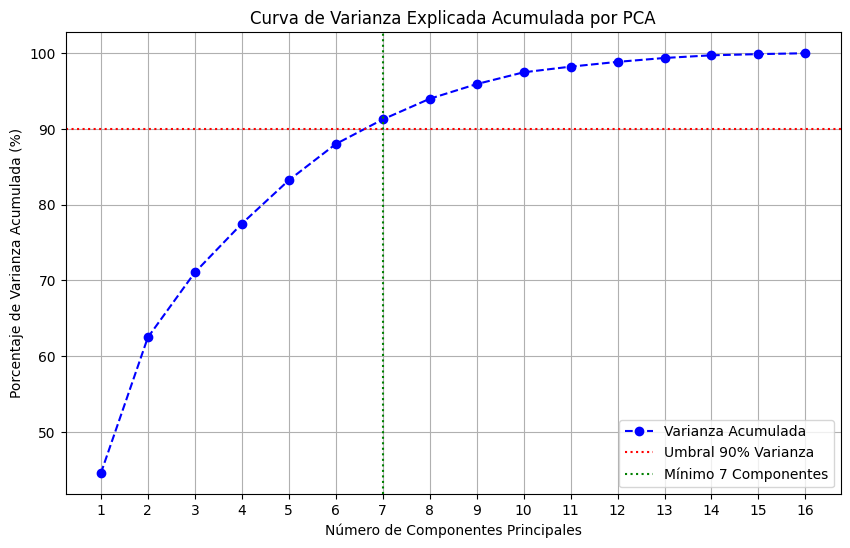

In [108]:

explained_variance_ratio = pca.explained_variance_ratio_ * 100

df_variance = pd.DataFrame(
    {
        "Componente": [f"PC{i+1}" for i in range(len(explained_variance_ratio))],
        "Varianza_Explicada_%": explained_variance_ratio,
        "Varianza_Acumulada_%": np.cumsum(explained_variance_ratio),
    }
)

print(df_variance.round(2))

cumulative_variance = np.cumsum(explained_variance_ratio)

n_components_90 = np.argmax(cumulative_variance >= 90) + 1
print(
    f"\nNúmero mínimo de componentes para explicar > 90% de la varianza: {n_components_90}"
)

plt.figure(figsize=(10, 6))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o",
    linestyle="--",
    color="b",
    label="Varianza Acumulada",
)

plt.axhline(
    y=90,
    color="r",
    linestyle=":",
    label="Umbral 90% Varianza",
)

plt.axvline(
    x=n_components_90,
    color="g",
    linestyle=":",
    label=f"Mínimo {n_components_90} Componentes",
)

plt.title("Curva de Varianza Explicada Acumulada por PCA")
plt.xlabel("Número de Componentes Principales")
plt.ylabel("Porcentaje de Varianza Acumulada (%)")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.grid(True)
plt.legend(loc="lower right")
plt.show()

8. Imprime la información de los componentes seleccionados (cargas o pesos de las variables originales) para interpretar qué variables contribuyen más a cada componente principal.
* Dibuja un diagrama de barras que muestre qué variables originales aportan más al primer componente principal (PC1), para visualizar su influencia relativa.

In [109]:
pc_df = pd.DataFrame((pca.components_[:n_components_90]), columns = X.columns, index=['Principal component {}'.format(i) for i in range(1, n_components_90 + 1)])
pc_df

,symboling,normalized_losses,wheel_base,length,width,height,curb_weight,num_cylinders,engine_size,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg
Principal component 1,-0.097417,0.015730,0.297827,0.337567,0.334154,0.113918,0.361949,0.245179,0.330140,0.262714,0.052419,0.015923,0.298459,-0.086676,-0.305762,-0.317429
Principal component 2,-0.402752,-0.330804,0.264598,0.138656,0.055178,0.421734,0.022448,-0.114115,-0.081608,0.003082,0.034366,0.360906,-0.276244,-0.363743,0.244770,0.195079
Principal component 3,0.265425,0.308304,-0.029492,-0.043866,0.108578,-0.282463,0.080318,0.176730,0.198927,-0.138240,0.511606,0.490226,0.009763,-0.256993,0.197583,0.191105
Principal component 4,-0.071656,-0.343111,-0.228250,-0.194123,-0.097712,-0.186128,-0.025091,0.552089,0.295503,0.040725,-0.430712,0.000951,0.165332,-0.289243,0.166746,0.156333
Principal component 5,-0.365914,-0.376068,-0.004383,-0.073522,-0.016414,-0.016741,-0.042322,0.236661,0.108753,-0.373004,0.571744,-0.233770,0.109046,0.341047,0.012215,0.007339
Principal component 6,0.173471,-0.492124,-0.183468,-0.082219,-0.107151,-0.214021,-0.013540,-0.354144,0.015613,0.511877,0.364450,-0.090066,0.065773,-0.281574,-0.107088,-0.078351
Principal component 7,0.127779,-0.322614,-0.106348,-0.008702,0.139884,-0.002597,0.061154,-0.068332,-0.073093,0.126249,-0.152706,0.614078,0.223857,0.604268,0.032927,0.046854


/tmp/ipykernel_2344/3663075557.py:1: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=pc_df.iloc[0:1],ci=None)


Text(0, 0.5, 'feature importance for PC1')

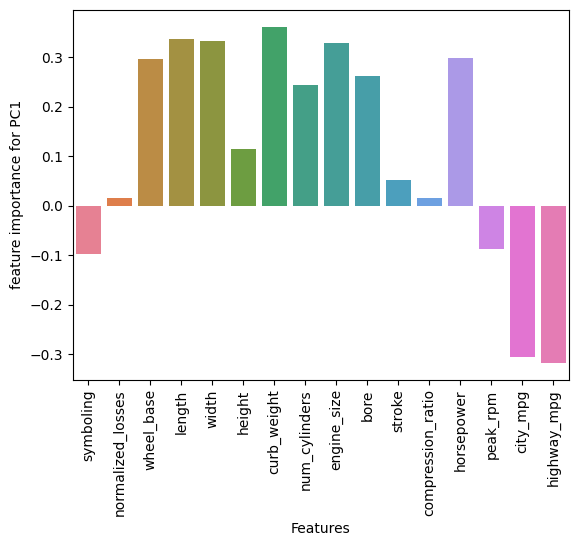

In [110]:
sns.barplot(data=pc_df.iloc[0:1],ci=None)
plt.xlabel('Features')
plt.xticks(rotation=90)
plt.ylabel('feature importance for PC1')

PC1 está dominado por curb_weight, length, width, engine_size y los mpg, es decir, tamaño y potencia frente a eficiencia

9. Codifica las variables categóricas mediante *One-Hot Encoding* y utiliza el parámetro `drop='first'` para evitar problemas de multicolinealidad entre las variables dummy generadas.

In [111]:
cat_cols = cars_df.select_dtypes(include='object').columns.tolist()
x_cat = cars_df[cat_cols]

imputer = SimpleImputer(strategy='most_frequent')
x_cat_imputed = imputer.fit_transform(x_cat)

encoder = OneHotEncoder(drop='first', sparse_output=False)
x_cat_encoder = encoder.fit_transform(x_cat_imputed)

cat_encoder_cols = encoder.get_feature_names_out(x_cat.columns)
df_cat_encoder = pd.DataFrame(x_cat_encoder, columns=cat_encoder_cols, index=cars_df.index)
print("Dataframe después de Encoder:")
df_cat_encoder.T

Dataframe después de Encoder:


,0,1,2,3,4,5,6,7,8,9,...,195,196,197,198,199,200,201,202,203,204
make_audi,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
make_bmw,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
make_chevrolet,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
make_dodge,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
make_honda,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
make_isuzu,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
make_jaguar,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
make_mazda,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
make_mercedes-benz,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
make_mercury,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


10. Conjunta, en un dataframe, las valores proyectados en los componentes seleccionados (mínimo), las transformaciones obtenidas de las variables categóricas y la variable de salida.
* Almacena el dataframe resultante en archivo.

In [112]:
X_pca_min = X_pca.iloc[:, :7]
X_pca_min.index = cars_df.index

final_X_pca = pd.concat([X_pca_min, df_cat_encoder, y], axis=1)

final_X_pca.to_csv('automobile_pca_dataset.csv', index=False)
display(final_X_pca.head())

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,make_audi,make_bmw,make_chevrolet,...,engine_type_ohcv,engine_type_rotor,fuel_system_2bbl,fuel_system_4bbl,fuel_system_idi,fuel_system_mfi,fuel_system_mpfi,fuel_system_spdi,fuel_system_spfi,price
0,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,13495
1,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,16500
2,0.634430,-1.372747,0.872496,0.998222,1.834717,-0.774751,-0.515065,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,16500
3,-0.361470,-0.919214,0.451578,-1.489124,-0.269938,-0.789900,0.000484,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,13950
4,1.172393,-1.794960,0.183773,-1.083812,0.113486,-0.861858,-0.353900,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,17450


---

**Declaración de uso de IA**



*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

---